# Control de cobertura de la condición inicial

**Pregunta:** ¿cambia el resultado de la selección de colocación al repartir los mismos nodos de condición inicial por todo el dominio?

La única intervención configurada es la ubicación de los 32 nodos IC. Se comparan las mismas diez semillas y tres métodos: Sobol, POD con 32 puntos guiados y PCA centrado + media con 64. Las estadísticas son descriptivas y pareadas por semilla. La referencia es la corrida instrumentada anterior, cuya reproducción ya había coincidido exactamente con el entrenamiento original.

Con IC distribuida, el menor RMSE medio de prueba corresponde a **Sobol**, con **0.1734**. Las tablas siguientes muestran tanto el efecto del cambio de IC como la comparación entre selectores.

## 1. Qué cambia y qué permanece fijo

| Elemento | Antes | Control |
|---|---|---|
| Nodos IC | Primeros 32 índices espaciales | 32 índices aproximadamente equiespaciados, incluidos ambos extremos |
| Pesos de datos, física e IC | 1, 1, 1 | 1, 1, 1 |
| Penalización separada de frontera | Ausente | Ausente |
| Puntos físicos activos | 128, renovados cada 100 pasos | Igual |
| Arquitectura / Adam / datos | Tres capas ocultas de ancho 32 / misma tasa y secuencia supervisada | Igual |
| Presupuesto | 100 pasos de calentamiento + 2000 de continuación | Igual |
| Semillas, candidatos y evaluación | Diez semillas; 4096 candidatos; evaluación independiente y tiempos reservados | Iguales por pareja |

Los 32 nodos IC se usan en t=0 y son un conjunto separado de los 128 puntos físicos activos. Las composiciones de colocación siguen siendo Sobol: 128 Sobol; POD: 32 guiados + 96 Sobol; PCA: 64 guiados + 64 Sobol. Los 32/64 puntos guiados no representan cantidades de componentes principales.

La distribución IC se aplica desde el calentamiento. Los pesos iniciales aleatorios son los mismos por semilla; el estado después del calentamiento puede cambiar como efecto de la intervención. Los tres selectores comparten ese nuevo estado dentro del control. Sus puntos seleccionados pueden cambiar después porque la historia del residuo también cambia: es una consecuencia del cambio de IC.

El intervalo entre nodos extremos pasa de [-1.0000, -0.7569] a [-1.0000, 1.0000]. La nueva distribución sigue usando solo 32 nodos discretos de 256; no impone IC en cada posición del continuo. La auditoría verifica igualdad de las divisiones de datos, las sondas, los datos de referencia y los candidatos para cada pareja.

**Ubicación de los 32 nodos de condición inicial**

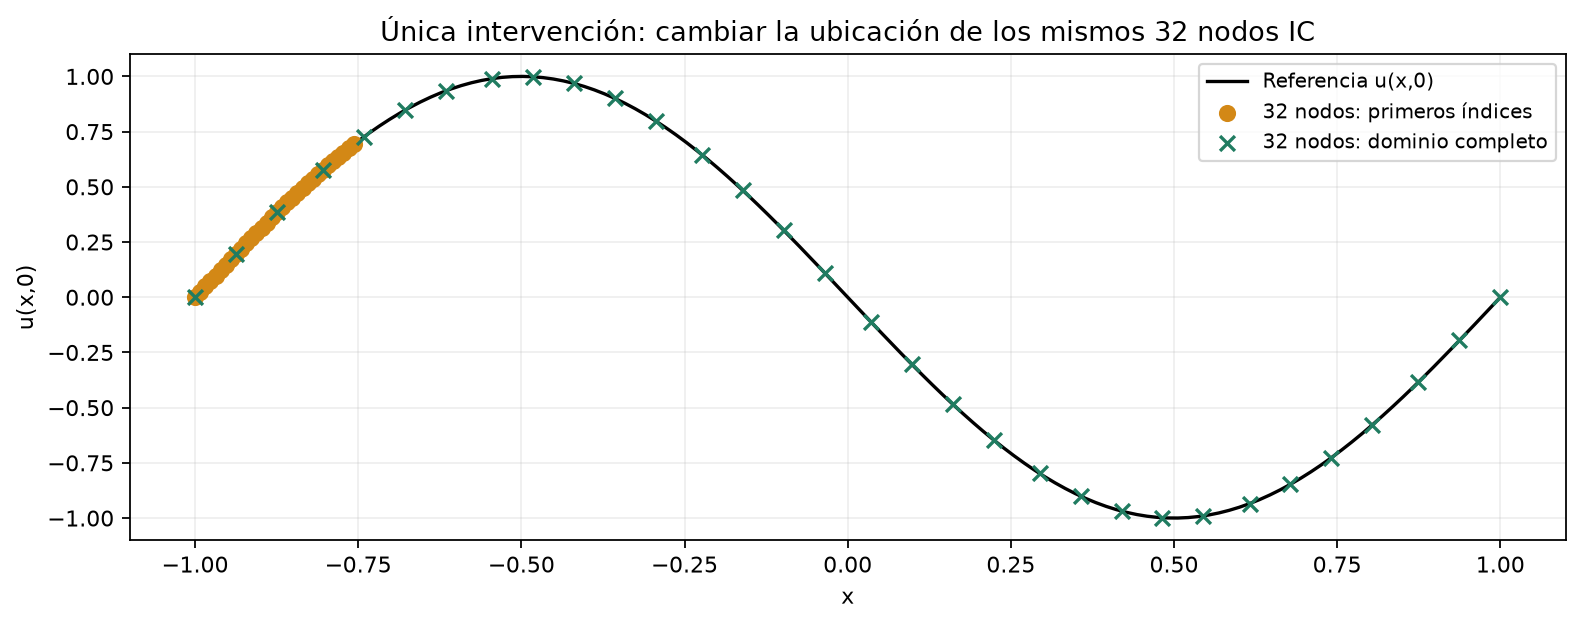

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/ic_nodes_before_after.png'), format='png', embed=True))


## 2. Efecto en la precisión de solución

| Método | Primeros 32 nodos | 32 distribuidos | Δ distribuida − anterior | Semillas con menor valor |
|---|---:|---:|---:|---:|
| Sobol | 0.1800 ± 0.0359 | 0.1734 ± 0.0362 | -0.0066 ± 0.0449 | 6/10 |
| POD: 32 puntos | 0.2124 ± 0.0554 | 0.1864 ± 0.0432 | -0.0260 ± 0.0381 | 8/10 |
| PCA + media: 64 puntos | 0.2298 ± 0.0572 | 0.2051 ± 0.0322 | -0.0247 ± 0.0532 | 7/10 |

RMSE en los mismos tiempos de prueba reservados por semilla. Cada celda es media ± DE entre semillas. La diferencia se calcula primero dentro de cada pareja, no restando desviaciones estándar. Un Δ negativo indica mejora. El conjunto de prueba no se utiliza para seleccionar nodos ni ajustar pesos.

## 3. Condición inicial global y residuo físico

### RMSE de IC en todos los nodos espaciales

| Método | Primeros 32 nodos | 32 distribuidos | Δ distribuida − anterior | Semillas con menor valor |
|---|---:|---:|---:|---:|
| Sobol | 0.2235 ± 0.0235 | 0.1525 ± 0.0183 | -0.0710 ± 0.0276 | 10/10 |
| POD: 32 puntos | 0.2525 ± 0.0292 | 0.1714 ± 0.0171 | -0.0812 ± 0.0258 | 10/10 |
| PCA + media: 64 puntos | 0.2656 ± 0.0286 | 0.1863 ± 0.0138 | -0.0793 ± 0.0260 | 10/10 |

La evaluación global permite comparar ambas ubicaciones. La pérdida IC de entrenamiento cambia los nodos donde se mide y no sustituye esta métrica.

### RMS del residuo en los 2048 puntos independientes

| Método | Primeros 32 nodos | 32 distribuidos | Δ distribuida − anterior | Semillas con menor valor |
|---|---:|---:|---:|---:|
| Sobol | 0.3664 ± 0.1474 | 0.5124 ± 0.1381 | 0.1460 ± 0.1879 | 2/10 |
| POD: 32 puntos | 0.1236 ± 0.0141 | 0.2160 ± 0.0218 | 0.0924 ± 0.0219 | 0/10 |
| PCA + media: 64 puntos | 0.1241 ± 0.0159 | 0.2108 ± 0.0217 | 0.0868 ± 0.0226 | 0/10 |

Una reducción del error de solución puede acompañarse de otro cambio en el residuo; se evalúan ambos criterios.

**Comparación de métricas antes y después**

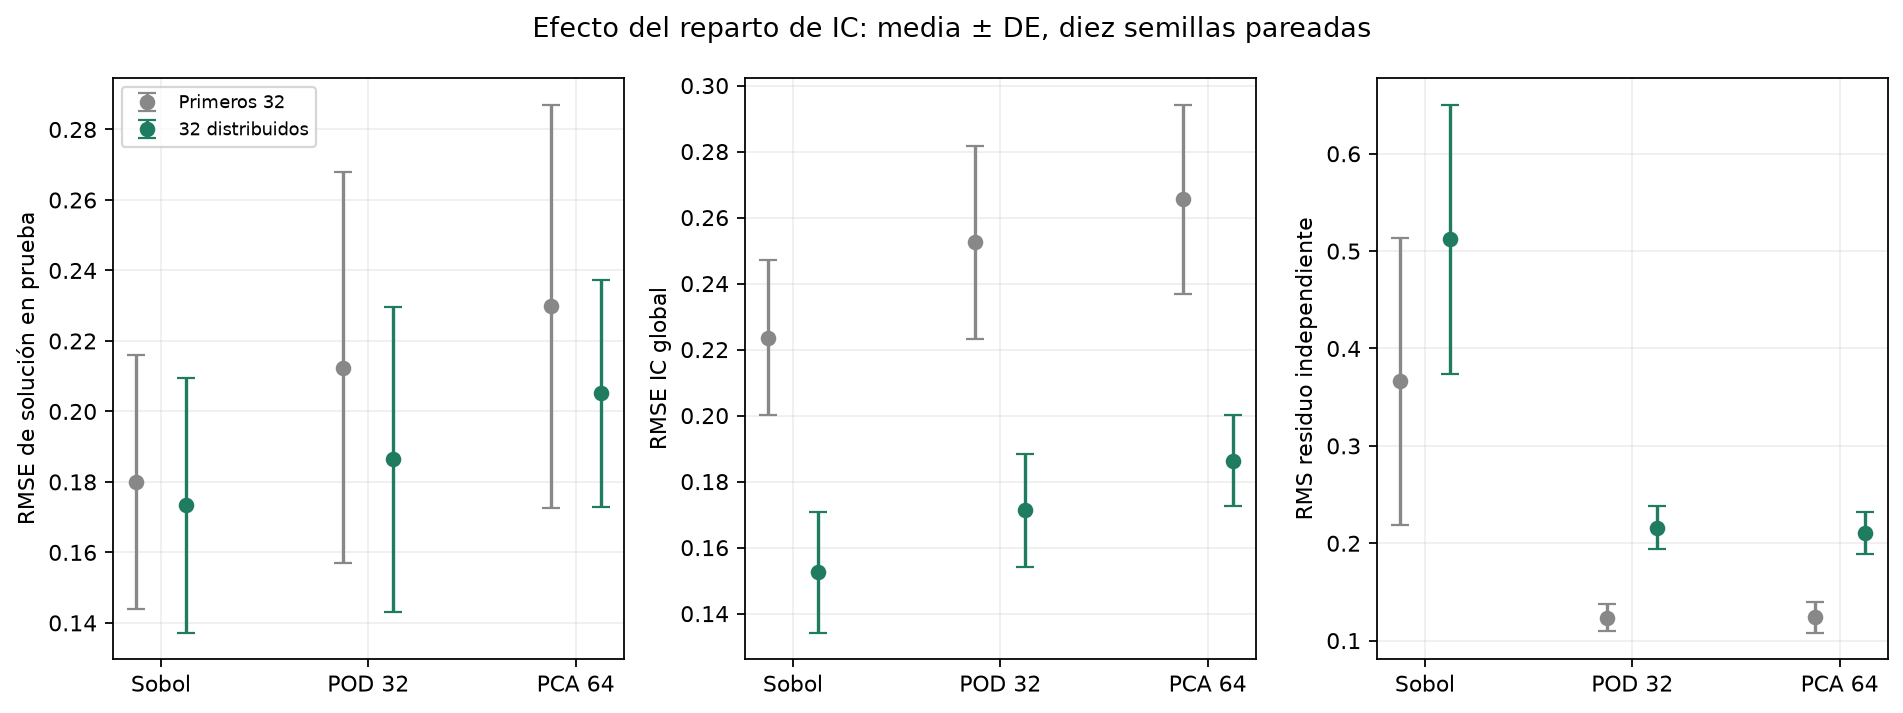

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/ic_control_metrics.png'), format='png', embed=True))


## 4. ¿Cambia la ventaja relativa frente a Sobol?

| Método | Brecha frente a Sobol: antes | Brecha: después | Cambio de brecha | Semillas que superan a Sobol después |
|---|---:|---:|---:|---:|
| POD: 32 puntos | 0.0324 ± 0.0372 | 0.0130 ± 0.0408 | -0.0194 ± 0.0549 | 4/10 |
| PCA + media: 64 puntos | 0.0498 ± 0.0345 | 0.0317 ± 0.0492 | -0.0181 ± 0.0652 | 2/10 |

La brecha es RMSE del método guiado menos RMSE de Sobol en la misma semilla. Una brecha negativa favorece al método guiado. Su cambio es (guiado−Sobol) con IC distribuida menos (guiado−Sobol) con IC anterior; un cambio negativo reduce la desventaja o amplía la ventaja del guiado. Todas las medias y DE se calculan sobre esas diferencias pareadas. Diez semillas y un único problema no prueban superioridad general.

**Precisión e IC global durante el entrenamiento**

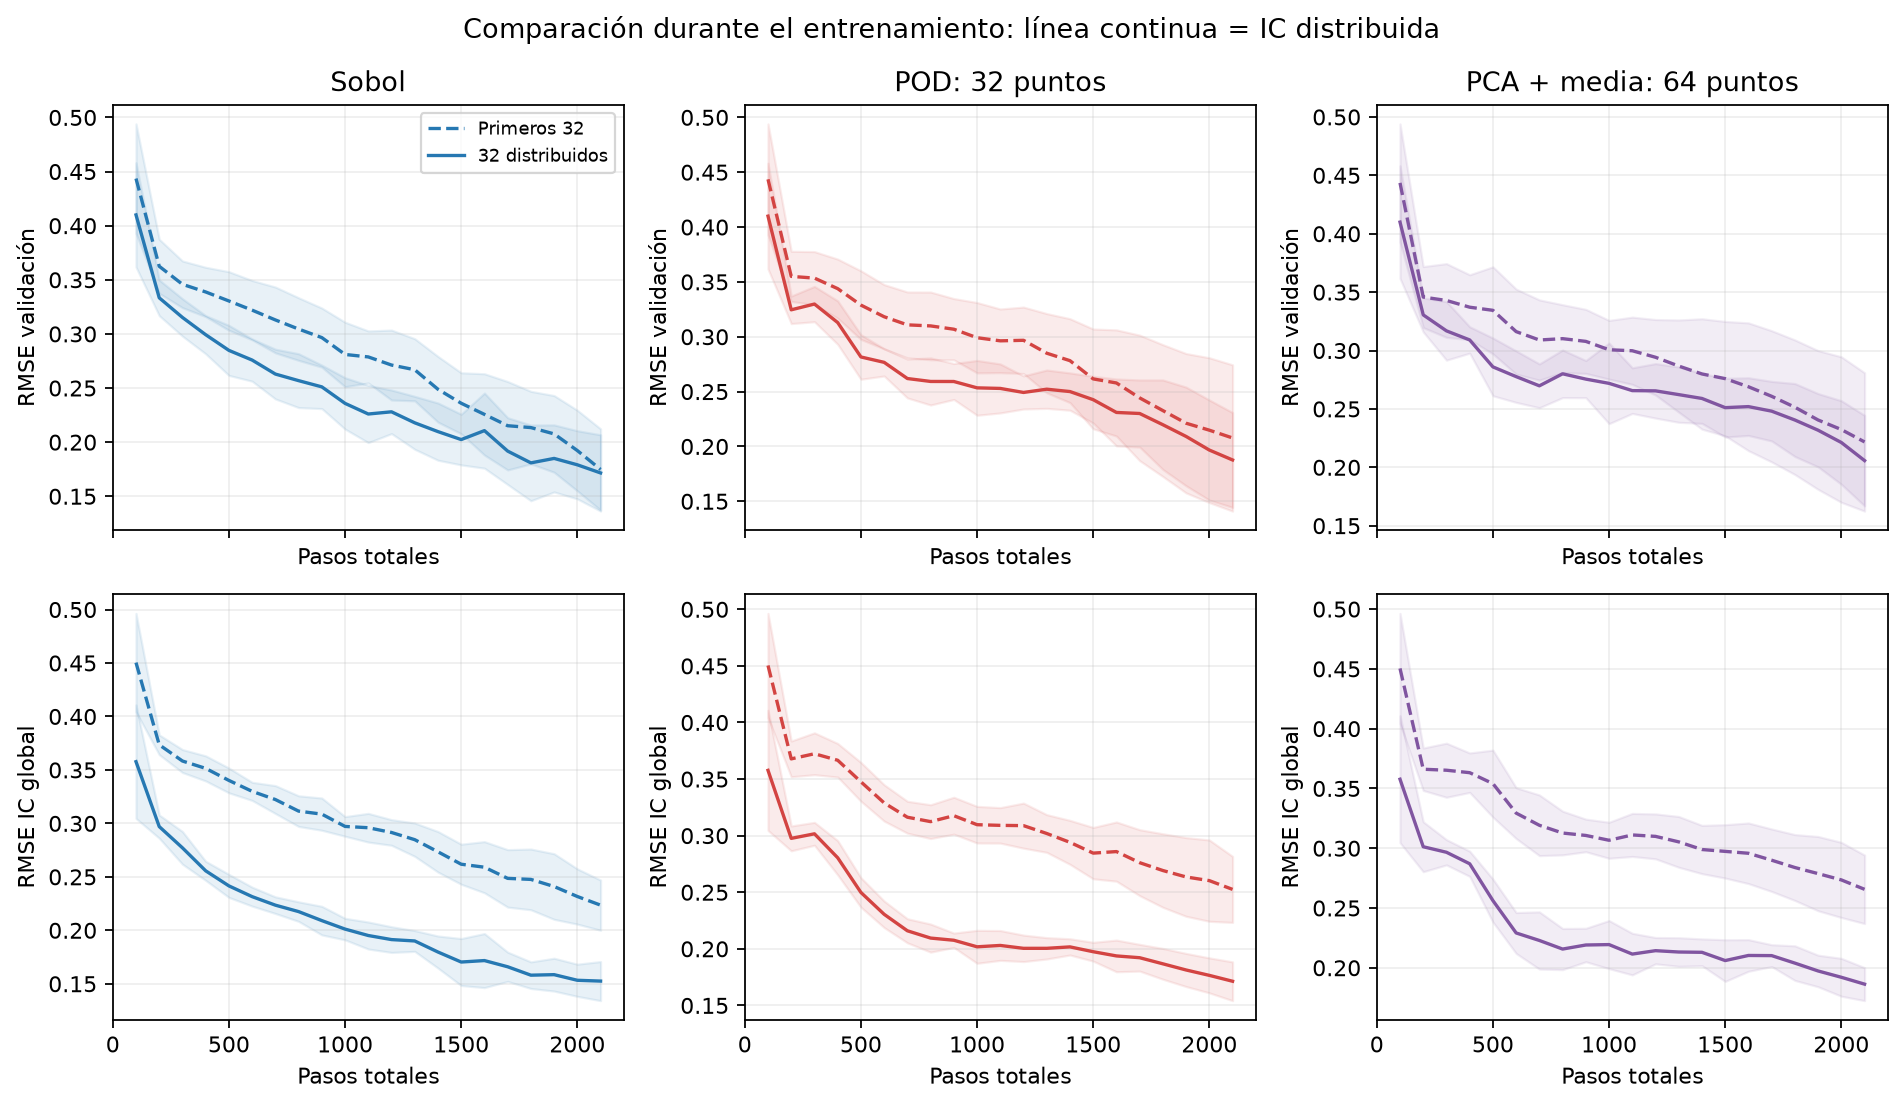

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/ic_control_trajectories.png'), format='png', embed=True))


## 5. Dónde cambia la solución

La semilla de las figuras detalladas es 2051, fijada antes de entrenar. El par de mapas usa la misma escala de error. Las imágenes abarcan tiempos de ajuste, validación y prueba para exploración; las métricas de generalización anteriores usan exclusivamente tiempos de prueba.

La ventana central tardía es |x| ≤ 0.1 y t ≥ 0.4. Se mantiene idéntica a la del diagnóstico, sin intervenir en el entrenamiento. Los RMSE siguientes se miden en tiempos de prueba; la región exterior es el complemento completo de esa ventana.

| Método | Ventana central: antes | Ventana central: después | Fuera de ventana: antes | Fuera de ventana: después |
|---|---:|---:|---:|---:|
| Sobol | 0.3736 ± 0.0976 | 0.4739 ± 0.1248 | 0.1579 ± 0.0293 | 0.1276 ± 0.0302 |
| POD: 32 puntos | 0.4352 ± 0.1588 | 0.4430 ± 0.1194 | 0.1873 ± 0.0433 | 0.1538 ± 0.0335 |
| PCA + media: 64 puntos | 0.4699 ± 0.1672 | 0.4733 ± 0.1002 | 0.2022 ± 0.0441 | 0.1714 ± 0.0231 |


**Mapas de error antes y después del cambio de IC**

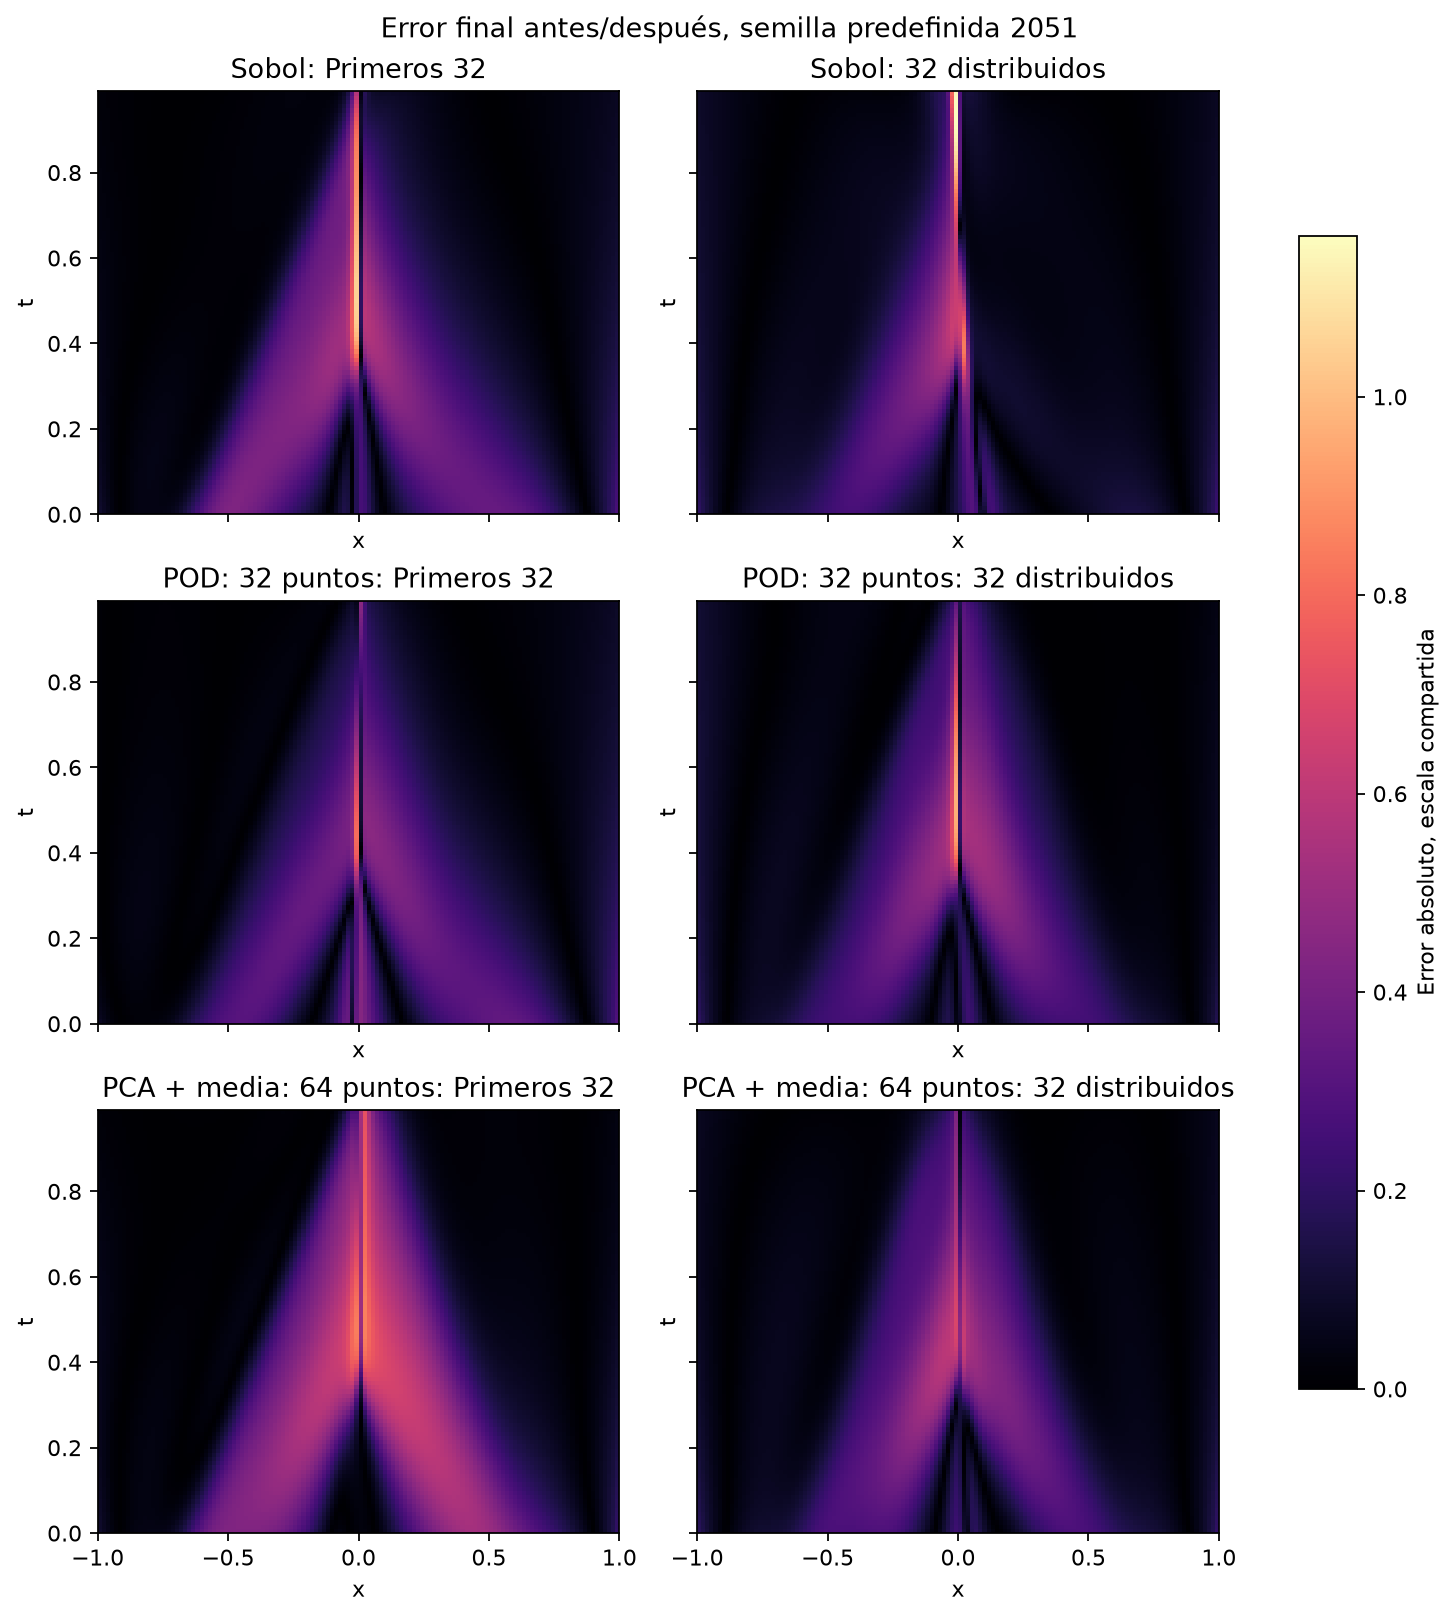

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/ic_control_error_maps.png'), format='png', embed=True))


**Perfiles del control con IC distribuida**

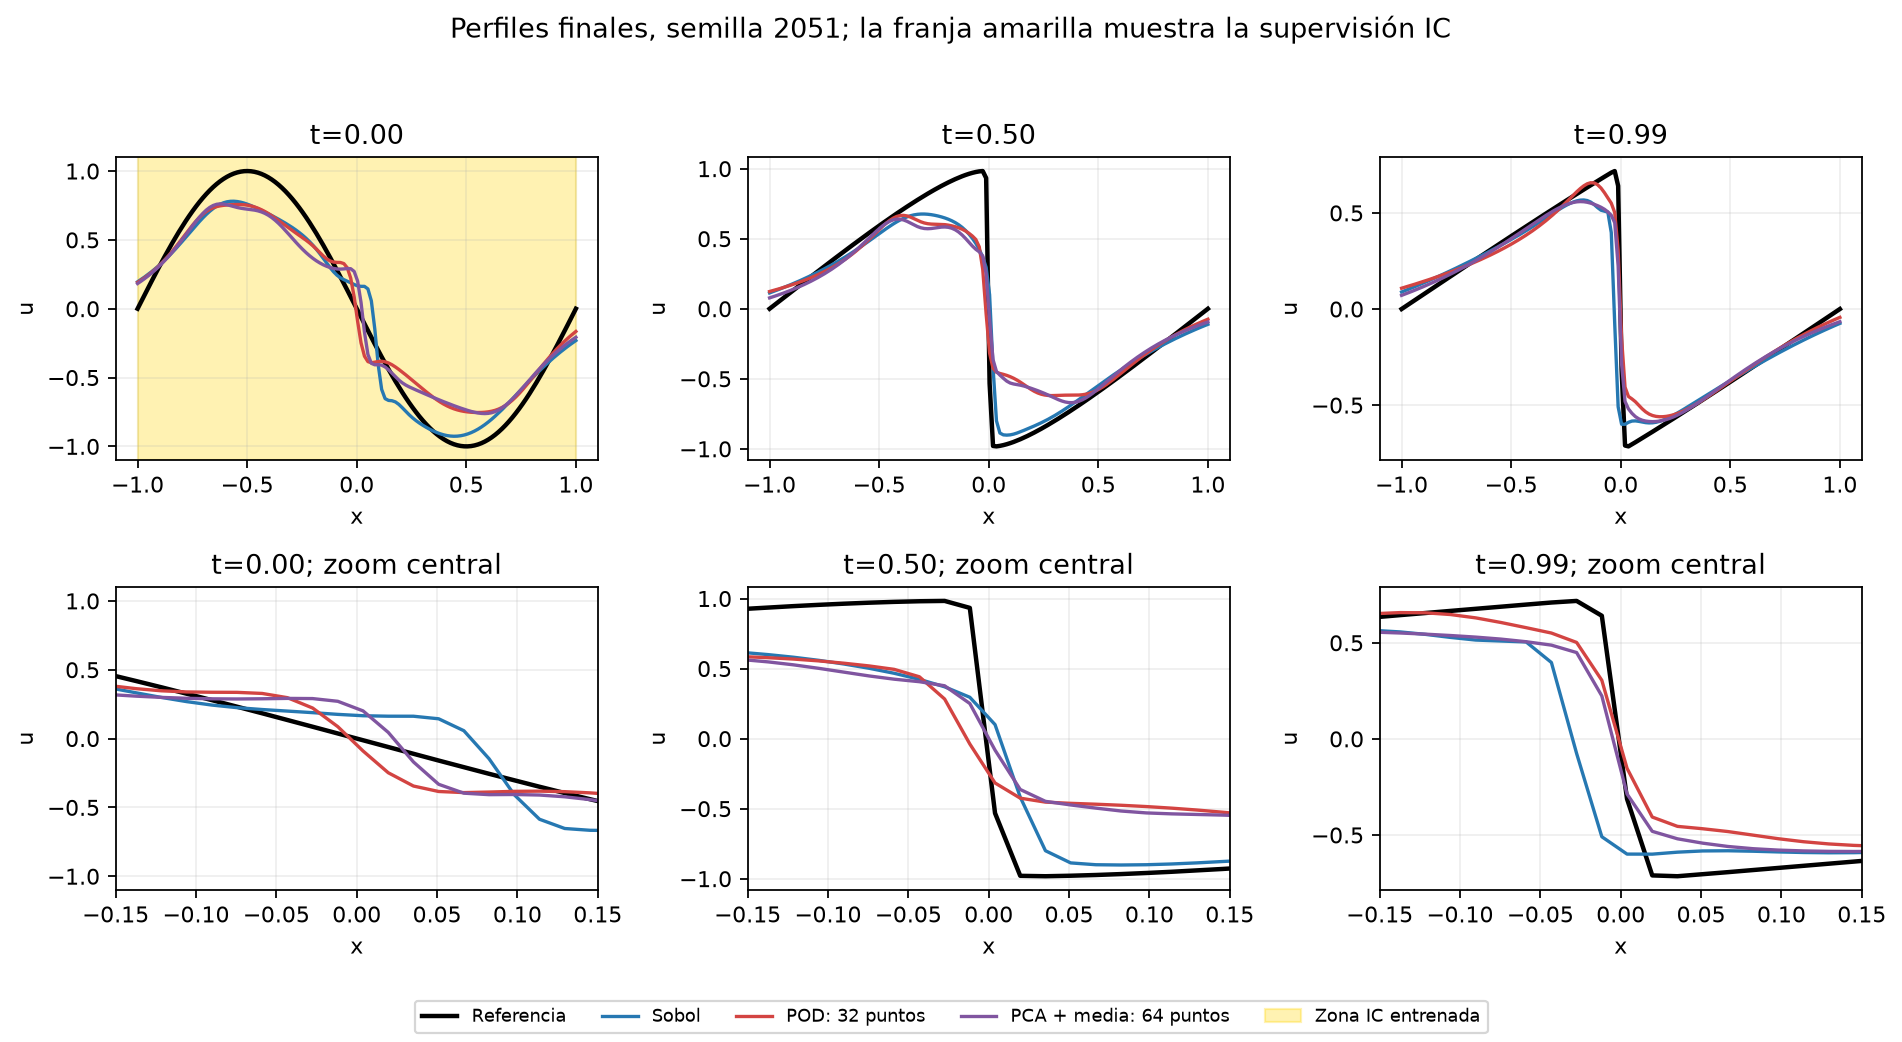

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/solution_profiles.png'), format='png', embed=True))


## 6. Mecanismo observado dentro del control

Las siguientes figuras corresponden al brazo con IC distribuida. Conservan las mediciones del diagnóstico: sonda física común fija y sonda activa de cada método, con los mismos datos supervisados y los nuevos nodos IC. Las normas son gradientes euclídeos de cada término; no incorporan los momentos ni el precondicionamiento de Adam. Un coseno negativo indica oposición local, sin demostrar por sí solo causalidad.

En pérdidas y normas, las líneas son medias y las bandas percentiles 16–84 de los valores positivos. En conflicto y cobertura, las bandas representan media ± DE. La comparación entre brazos de la norma de IC corresponde deliberadamente a dos conjuntos de nodos distintos.

**Pérdidas del control**

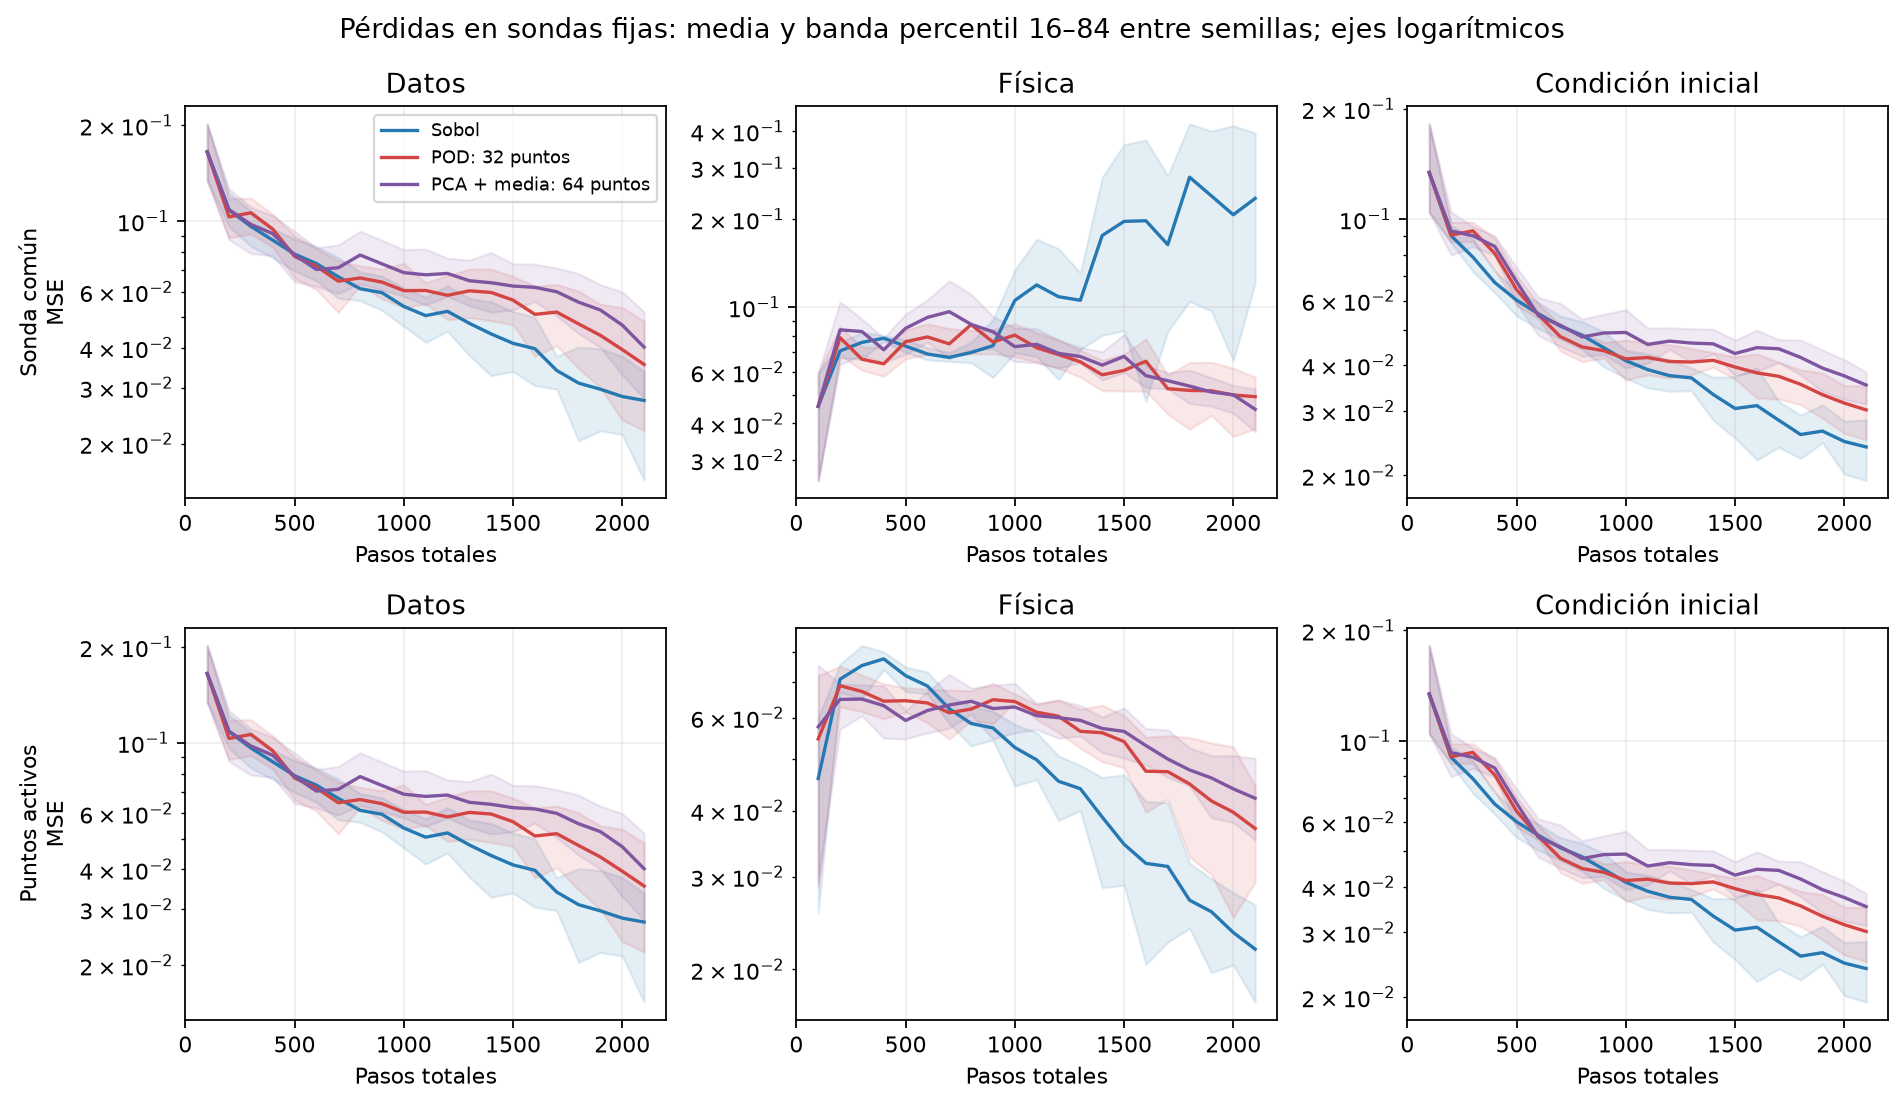

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/loss_components.png'), format='png', embed=True))


**Normas de gradiente del control**

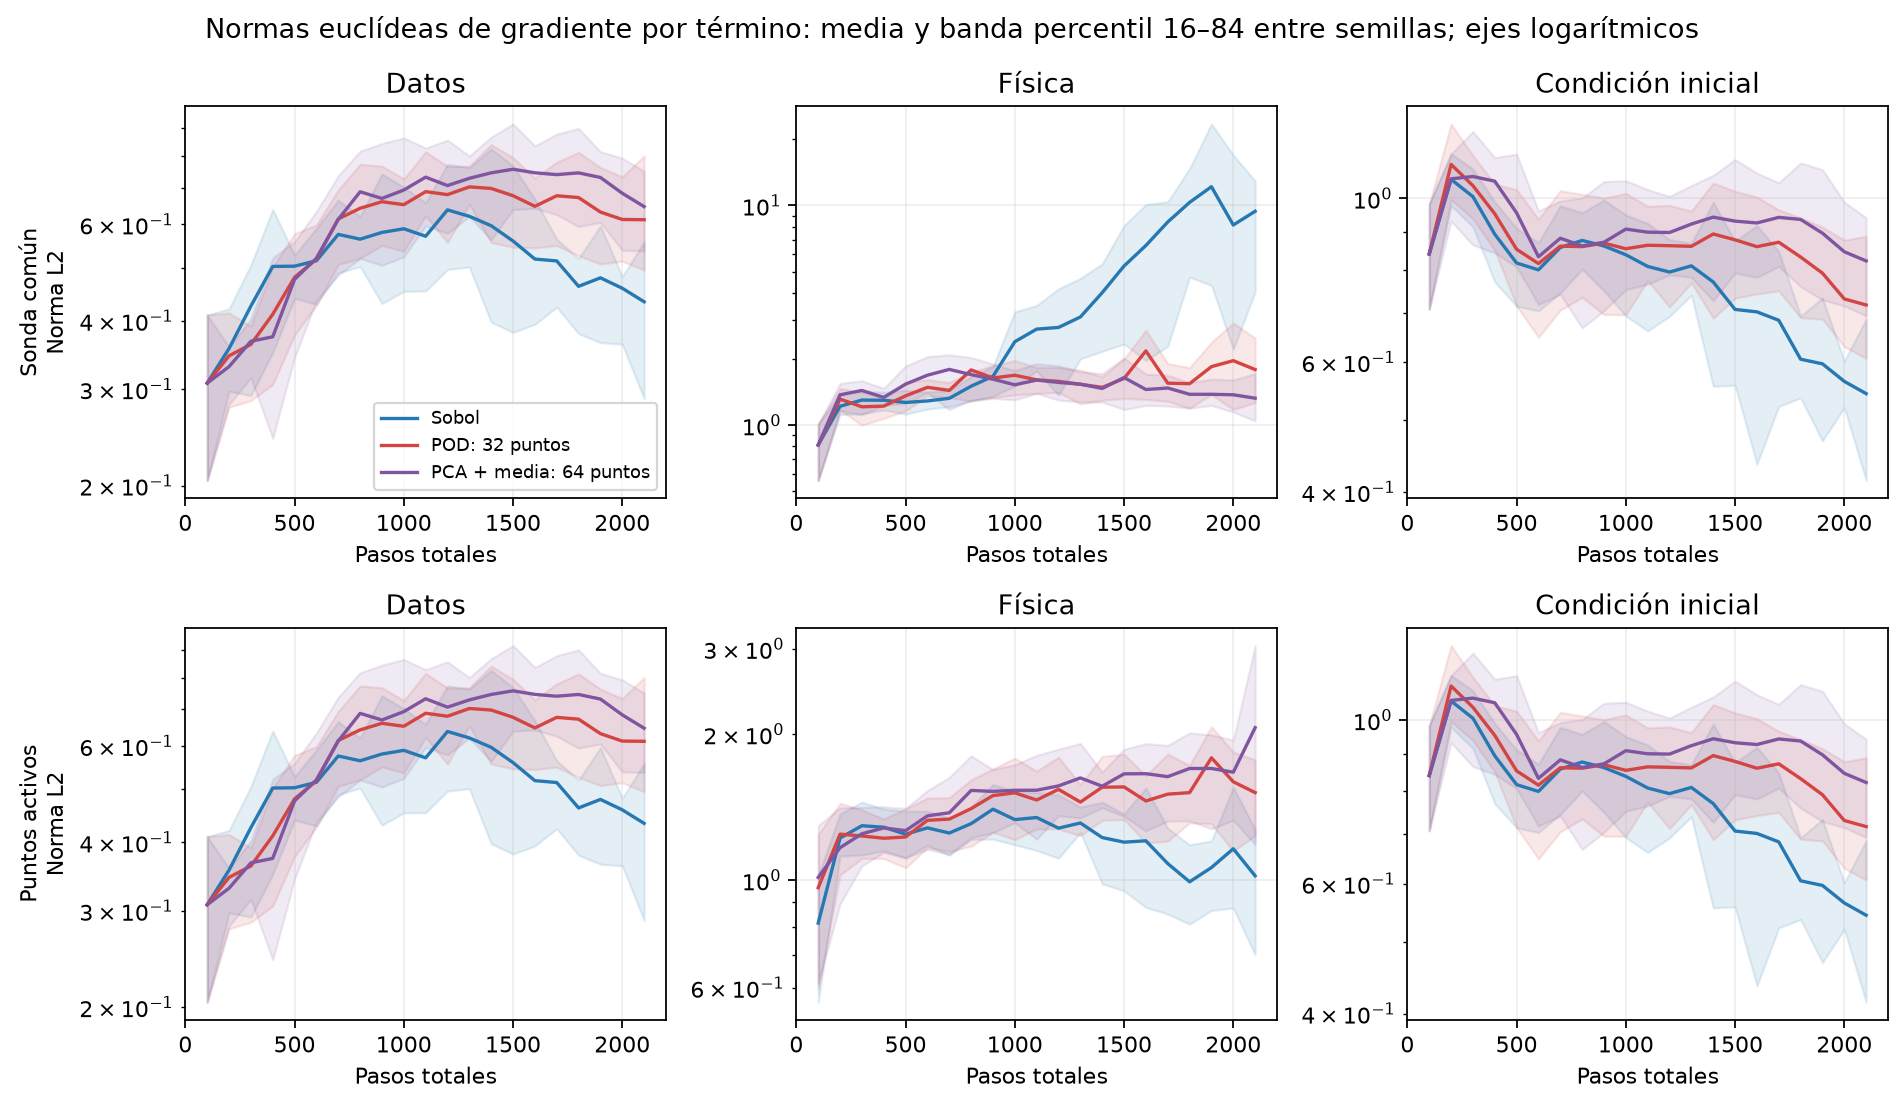

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/grad_components.png'), format='png', embed=True))


**Conflicto de gradientes del control**

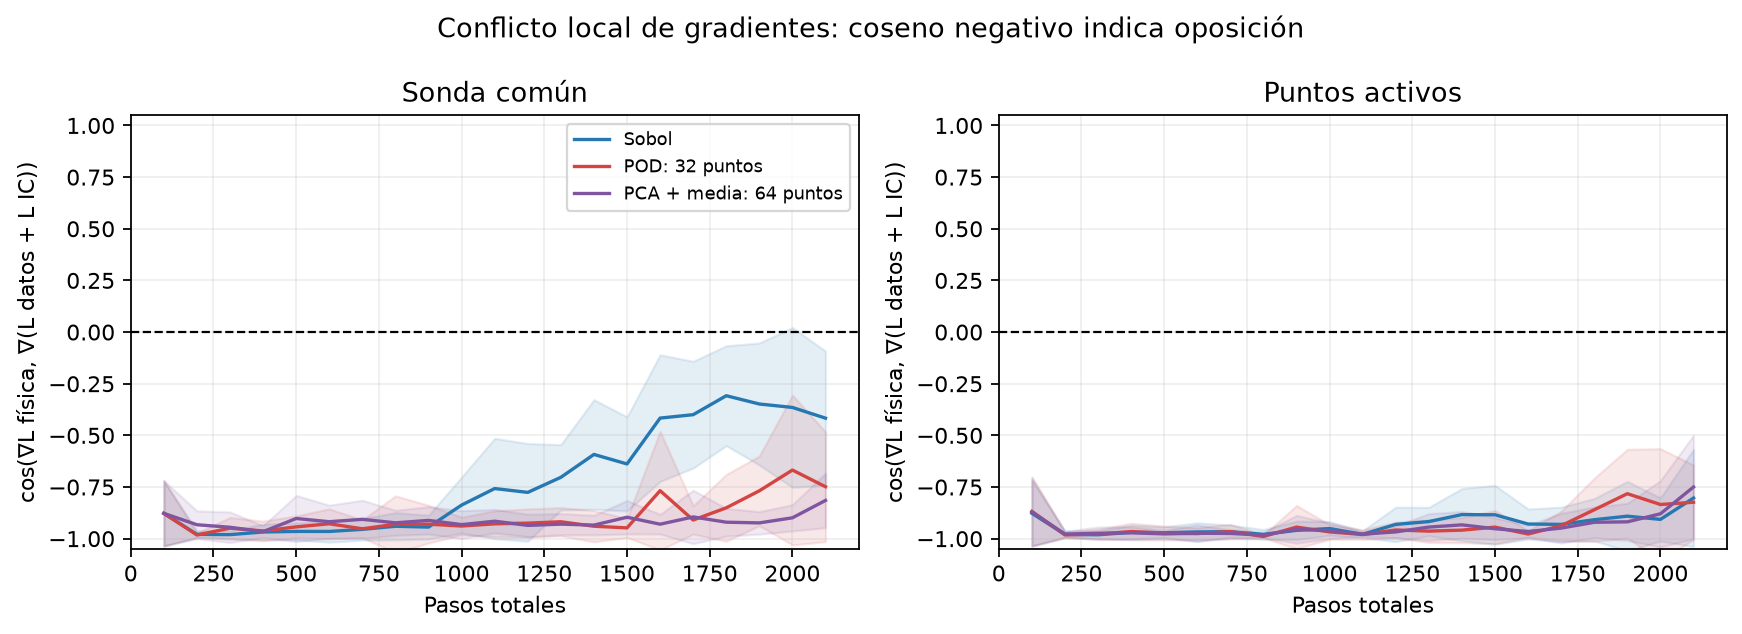

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/gradient_conflict.png'), format='png', embed=True))


**Puntos seleccionados con IC distribuida**

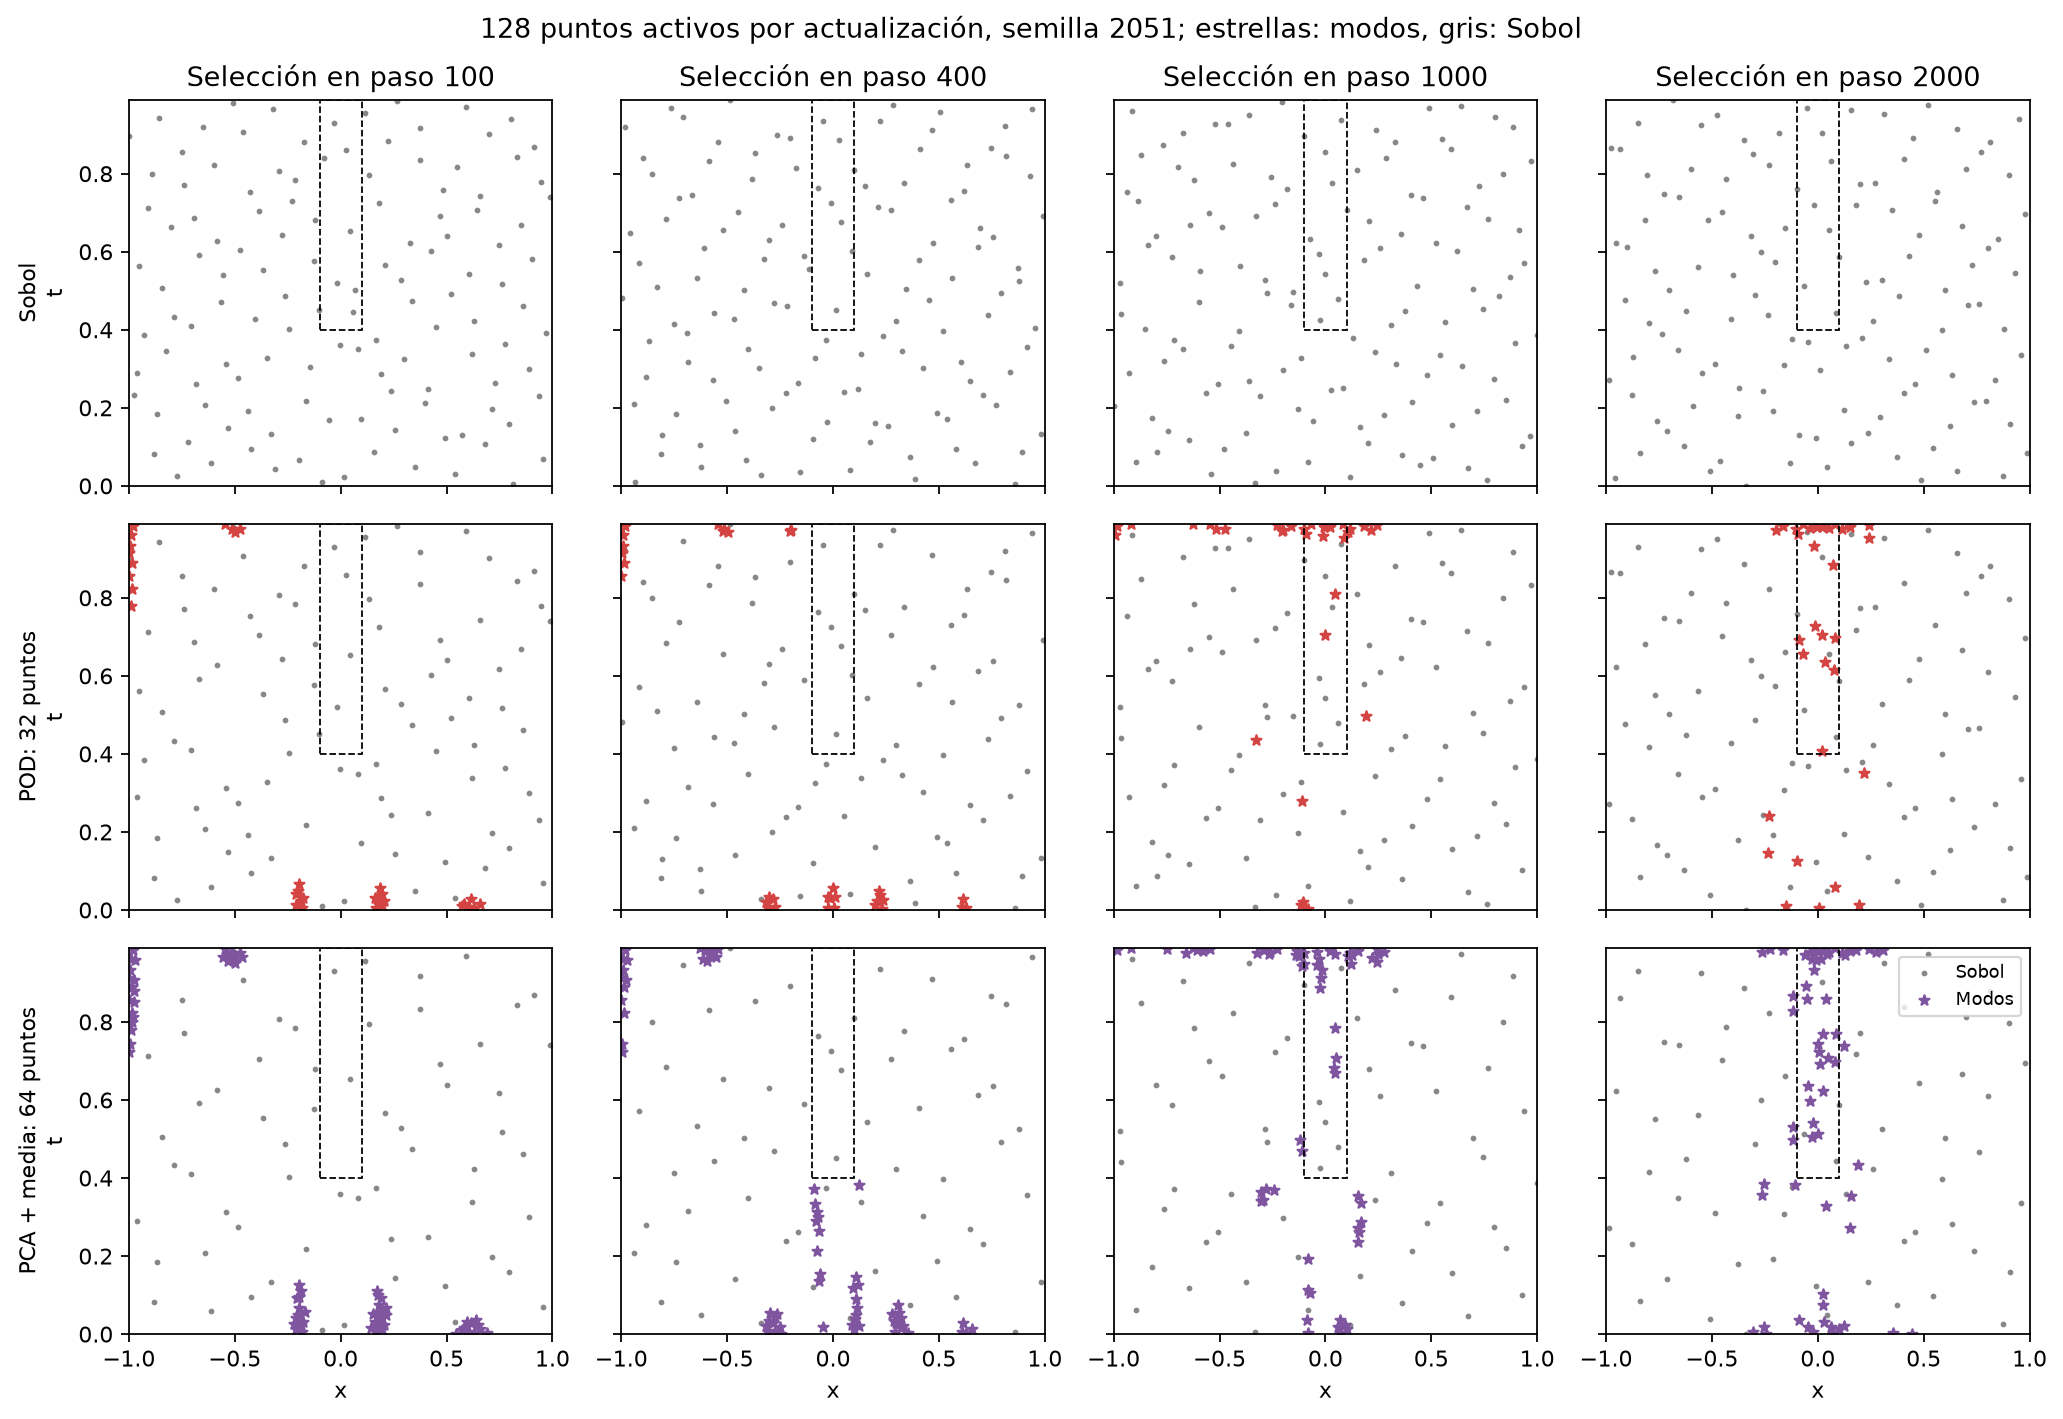

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/selected_points_evolution.png'), format='png', embed=True))


**Cobertura de colocación con IC distribuida**

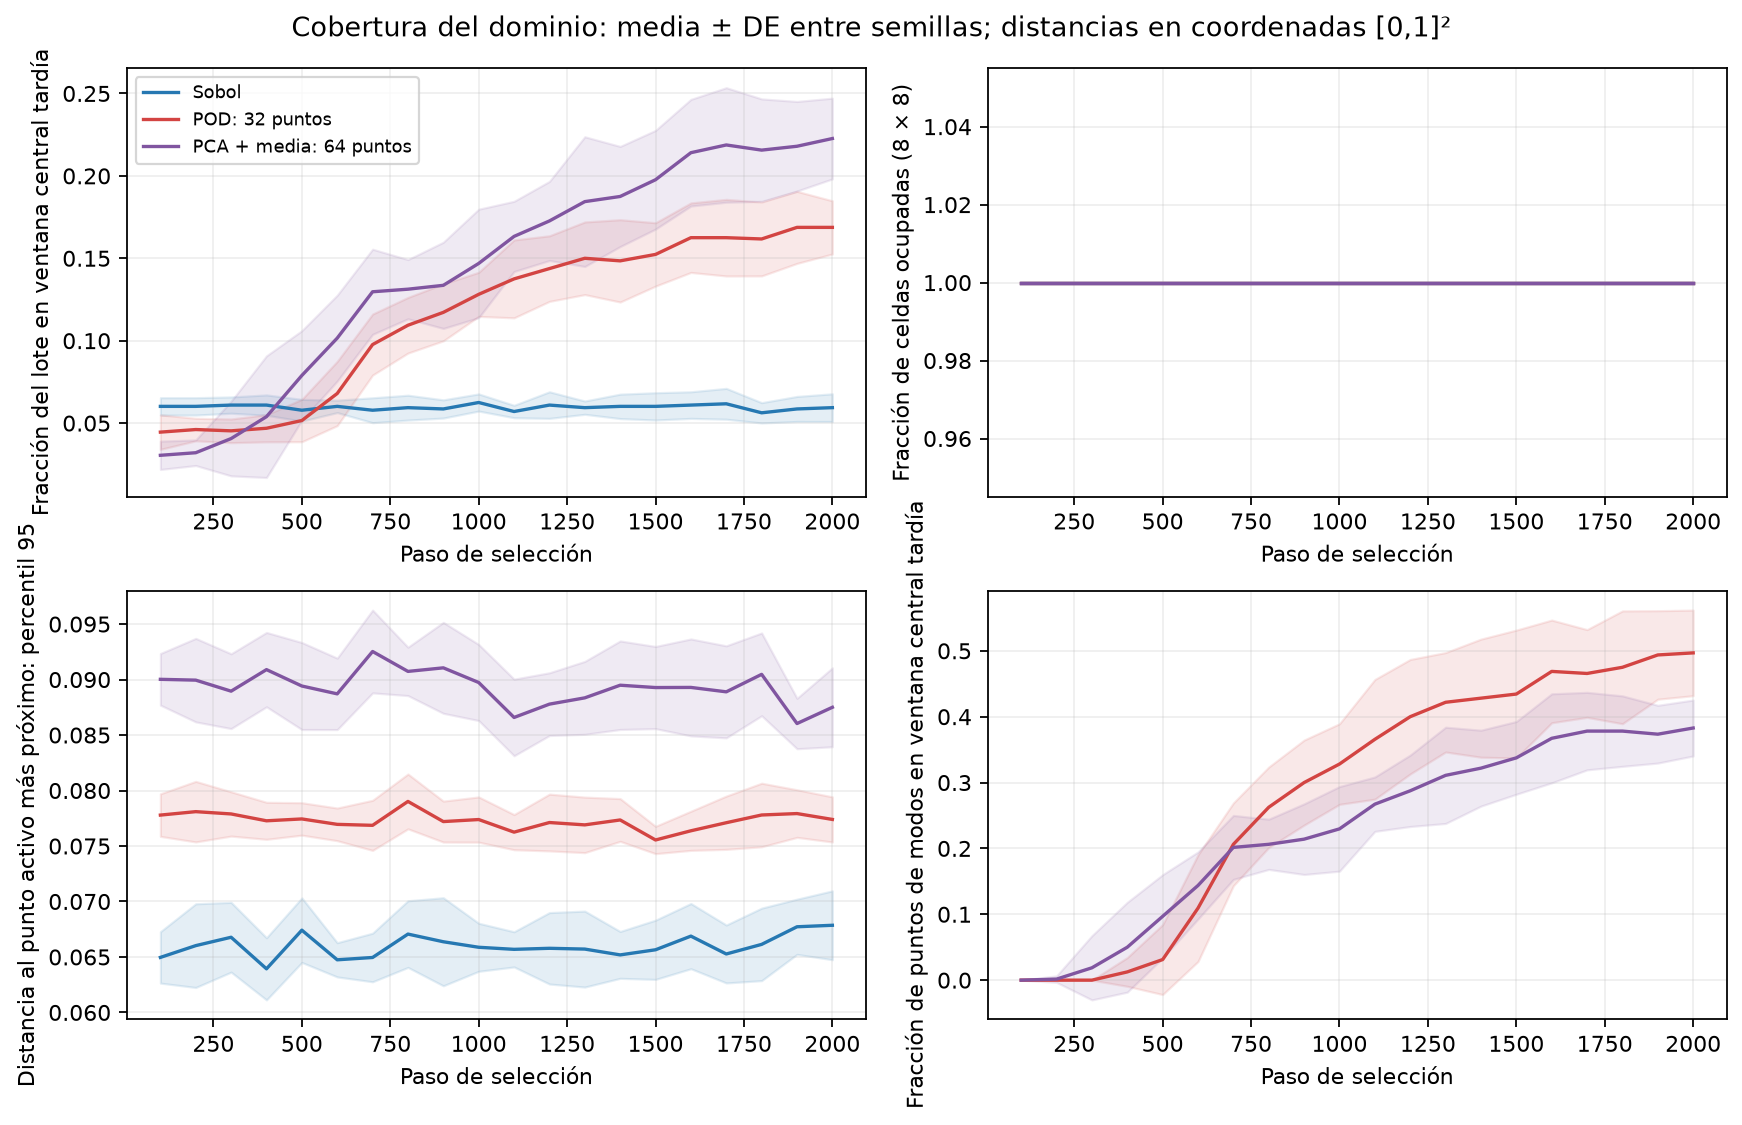

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_coverage_control/ic_uniform_domain_10_seeds_2k_v1/coverage_evolution.png'), format='png', embed=True))


## 7. Lectura del control

- **Sobol**: IC global mejora en 10/10 semillas; el RMSE de solución mejora en 6/10 y el residuo físico en 2/10.
- **POD: 32 puntos**: IC global mejora en 10/10 semillas; el RMSE de solución mejora en 8/10 y el residuo físico en 0/10.
- **PCA + media: 64 puntos**: IC global mejora en 10/10 semillas; el RMSE de solución mejora en 7/10 y el residuo físico en 0/10.

El residuo físico independiente aumenta en media en los tres métodos. La mejora de IC global no equivale a una mejora de todas las métricas. El cambio de distribución modifica el compromiso que alcanza el optimizador con los mismos pesos de pérdida.

Las brechas medias frente a Sobol se interpretan junto con su variabilidad pareada; reducir una brecha media no demuestra que el método guiado supere a Sobol de forma consistente.

## 8. Alcance y reproducción

Este control permite atribuir el cambio observado del pipeline a la intervención de ubicación IC, dentro de las parejas y del protocolo especificado. No identifica todos los mecanismos internos ni garantiza generalización a otras ecuaciones. La distribución física y los modos pueden evolucionar como consecuencia de esa intervención. No se añade un término de frontera ni se seleccionan nuevos pesos a partir de la prueba.

La referencia anterior se reutiliza; `summary.json` guarda la configuración invariable, las estrategias de IC, las auditorías por semilla y las huellas SHA-256 de las métricas de referencia. `paired_changes_by_seed.csv` conserva cada diferencia y `method_gap_changes.csv` las comparaciones frente a Sobol. Cada carpeta de semilla contiene los puntos activos, gradientes, campos, parámetros y métricas. Las mediciones de tiempo incluyen la instrumentación y no sustentan una afirmación de aceleración.

```powershell
python scripts/run_ic_coverage_control.py
python scripts/run_ic_coverage_control.py --report-only
```

Las figuras se conservan como PNG/SVG en los resultados y como PNG incrustado en este notebook. El [diagnóstico anterior](10_residual_balance_diagnostics.ipynb) documenta el brazo de referencia.